In [1]:
!pip list 2>/dev/null | grep -i -E "^(keras|keras-hub|keras-nlp|tensorflow) "

keras                                 3.15.1
keras-hub                             0.33.0
keras-nlp                             0.26.0
tensorflow                            2.21.0


In [2]:
%pip install -q --upgrade keras-hub

Note: you may need to restart the kernel to use updated packages.


In [3]:
# Kaggle setup: install only KerasHub for the optional pretrained Swin control.
import importlib.util, subprocess, sys
if importlib.util.find_spec("keras_hub") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "keras-hub"])

In [4]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"   # must be set BEFORE importing Keras

import gc, json, time, random, hashlib, platform
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras_hub
import tensorflow as tf
from tensorflow.keras import layers
import sklearn
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
)
from IPython.display import display

print("Python      :", platform.python_version())
print("TensorFlow  :", tf.__version__)
print("Keras       :", tf.keras.__version__)
print("NumPy       :", np.__version__)
print("scikit-learn:", sklearn.__version__)

Python      : 3.13.16
TensorFlow  : 2.21.0
Keras       : 3.15.1
NumPy       : 2.1.3
scikit-learn: 1.6.1


In [5]:
gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
print("GPU(s):", gpus or "none (Swin training will be very slow on CPU)")

GPU(s): [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [ ]:
# COMMON CONFIGURATION: edit this cell for every experiment.
SEED = 42
DATASET_ROOT = "/kaggle/input/datasets/miranibrahim/lung-cancer-mendely-dataset/Lung_Cancer_Augmented_Dataset_V4"
MODELS_DIR = "/kaggle/working/Lung_Cancer_Classification_Results/models"
CHECKPOINTS_DIR = "/kaggle/working/Lung_Cancer_Classification_Results/checkpoints"
RESULTS_DIR = "/kaggle/working/Lung_Cancer_Classification_Results"
SPLIT_FOLDER_NAMES = {"train": ["train", "training"], "val": ["valid", "val", "validation"], "test": ["test", "testing"]}

IMAGE_SIZE = (224, 224)              # square; 224 is required by the pretrained preset
BATCH_SIZE = 16                       # 4/8 for limited GPU memory; 16+ on larger GPUs
EPOCHS = 30                          # max; early stopping usually stops sooner
LEARNING_RATE = 10e-3                 # scratch Swin: 1e-4 to 5e-4; too high can destabilize training
PRETRAINED_LEARNING_RATE = 1e-5      # smaller rate for fine-tuning ImageNet-pretrained Swin
OPTIMIZER_NAME = "adamW"             # adamw recommended for transformers; alternatives: adam, sgd, rmsprop
WEIGHT_DECAY = 0                  # 0 disables; try 1e-4 to 5e-2 for regularization with AdamW
SGD_MOMENTUM = 0.9
EARLY_STOPPING_PATIENCE = 7         # stop after this many epochs without val-loss improvement
REDUCE_LR_PATIENCE = 4               # lower LR when validation loss stalls
REDUCE_LR_FACTOR = 0.5
MIN_LEARNING_RATE = 1e-6
LR_SCHEDULER = "reduce_on_plateau"  # alternatives: "none"
DROPOUT_RATE = 0.1                   # 0.0-0.5; increase to reduce overfitting
USE_AUGMENTATION = False             # True for mild transforms; dataset V4 is already augmented
AUGMENTATION_CONFIG = {"flip": "horizontal", "rotation": 0.03, "zoom": 0.05}  # flip: horizontal/vertical; rotation/zoom are fractions
USE_CLASS_WEIGHTS = True             # keep same across variants; helps if class counts are imbalanced
USE_MIXED_PRECISION = True           # GPU speed/memory; final output remains float32
CHECK_DUPLICATES = True              # exact hashes across splits; not augmented near-duplicates
SHOW_FULL_SUMMARY = False            # True prints full Keras summaries for model debugging
RUN_SELF_TESTS = True



# Loss: sparse CE uses integer labels; other options use one-hot labels.
LOSS_FUNCTION_NAME = "categorical_crossentropy_label_smoothing"  # sparse_categorical_crossentropy, categorical_crossentropy, categorical_crossentropy_label_smoothing, categorical_focal_crossentropy
# *** entropy regularization  ***
LABEL_SMOOTHING = 0.05               # 0.0-0.15; used only by smoothed CE / focal loss
FOCAL_GAMMA = 2.0                    # 1-3; only for categorical_focal_crossentropy
FOCAL_ALPHA = 0.25                   # focal class scaling

HEAD_CONFIG = {
    "pooling": "avg",               # "avg" or "max". Use "avg" to capture overall feature information; "max" to focus on strongest features.
    "hidden_units": [],             # [] (no hidden layer), [128], [256], or [256, 128]. Use [] for a simpler head; larger units for more learning capacity.
    "activation": "gelu",           # "relu", "gelu", or "swish". ReLU is a common default; GELU/Swish may work better with Transformer features.
    "dropout_rate": DROPOUT_RATE    # 0.0–0.5. Use 0.0 without dropout; 0.2–0.3 for moderate regularization; 0.5 for stronger regularization when overfitting.
}

# Custom Swin variants are trained from scratch: no pretrained weights match altered architectures.
SWIN_BASELINE_CONFIG = {  # fixed Swin-Tiny-style reference; change only for a new baseline
    "patch_size": 4,                 # pixels per patch; 2 keeps finer detail but costs more memory
    "window_size": 7,                # local attention window; 4/7 are common; must divide stage grids
    "embed_dim": 96,                 # initial channel width; 48/64 smaller, 96 standard Swin-Tiny
    "num_heads": [3, 6, 12, 24],     # heads per stage; each stage width must be divisible by its head count
    "depths": [2, 2, 6, 2],          # blocks per stage; fewer blocks train faster on small datasets
    "mlp_ratio": 4.0,                 # MLP expansion; 2-4 trades capacity for speed
    "dropout_rate": 0.0,              # 0-0.2; regularize when training overfits
    "attention_dropout_rate": 0.0,    # 0-0.1; attention regularization for small/noisy data
    "drop_path_rate": 0.1,             # 0-0.2; stochastic depth for deeper networks
    "qkv_bias": True,                  # attention projection bias; False is an ablation
    "use_shifted_window": True,        # False removes cross-window shifted attention
    "use_relative_position_bias": True,# False removes spatial offset bias
}
SWIN_CONFIG = {  # proposed compact model; add named entries to PROPOSED_CONFIGS for more ablations
    "patch_size": 4, "window_size": 7, "embed_dim": 64,   # patch/window as above; smaller width uses less GPU memory
    "num_heads": [2, 4, 8, 16], "depths": [2, 2, 4, 2],   # smaller heads/depths suit small datasets
    "mlp_ratio": 3.0, "dropout_rate": 0.1,                # 2-4 MLP expansion; dropout 0-0.2
    "attention_dropout_rate": 0.0, "drop_path_rate": 0.1, # raise mildly if validation overfits
    "qkv_bias": True, "use_shifted_window": True, "use_relative_position_bias": True,
}
PROPOSED_CONFIGS = {"SwinTransformer": SWIN_CONFIG}
# Exact KerasHub ImageNet preset; requires Kaggle internet access. This transfer control is NOT part of the scratch Swin pair.
INCLUDE_PRETRAINED_SWIN = True
SWIN_PRESET = "swin_tiny_patch4_window7_224"
PRETRAINED_SWIN_TRAINABLE = True  # True fine-tunes backbone; False trains only its classifier head
MODEL_NAMES = ["SwinBaseline", *PROPOSED_CONFIGS]
if INCLUDE_PRETRAINED_SWIN:
    MODEL_NAMES.append("SwinPretrained")

WEIGHT_DECAY = float(WEIGHT_DECAY)
if LOSS_FUNCTION_NAME not in {"sparse_categorical_crossentropy", "categorical_crossentropy", "categorical_crossentropy_label_smoothing", "categorical_focal_crossentropy"}:
    raise ValueError(f"Unsupported loss: {LOSS_FUNCTION_NAME}")
LABEL_MODE = "int" if LOSS_FUNCTION_NAME == "sparse_categorical_crossentropy" else "categorical"
if OPTIMIZER_NAME.lower() not in {"adamw", "adam", "sgd", "rmsprop"}:
    raise ValueError(f"Unsupported optimizer: {OPTIMIZER_NAME}")
if LR_SCHEDULER not in {"reduce_on_plateau", "none"}:
    raise ValueError("LR_SCHEDULER must be 'reduce_on_plateau' or 'none'.")

random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
if USE_MIXED_PRECISION and tf.config.list_physical_devices("GPU"):
    tf.keras.mixed_precision.set_global_policy("mixed_float16")
else:
    tf.keras.mixed_precision.set_global_policy("float32")
RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S")
RUN_DIR = Path(RESULTS_DIR) / f"run_{RUN_ID}"
HISTORIES_DIR, METRICS_DIR = RUN_DIR / "histories", RUN_DIR / "metrics"
GRAPHS_DIR, PREDICTIONS_DIR = RUN_DIR / "graphs", RUN_DIR / "predictions"
for folder in (Path(MODELS_DIR), Path(CHECKPOINTS_DIR), HISTORIES_DIR, METRICS_DIR, GRAPHS_DIR, PREDICTIONS_DIR):
    folder.mkdir(parents=True, exist_ok=True)
print("Models:", MODEL_NAMES, "| labels:", LABEL_MODE, "| output:", RUN_DIR)

Models: ['SwinBaseline', 'SwinTransformer', 'SwinPretrained'] | labels: categorical | output: /kaggle/working/Lung_Cancer_Classification_Results/run_20261126_120222


In [21]:
VALID_MODELS = {"SwinBaseline", "SwinPretrained", *PROPOSED_CONFIGS}
if not MODEL_NAMES or len(set(MODEL_NAMES)) != len(MODEL_NAMES):
    raise ValueError("MODEL_NAMES must contain one or more unique model names.")
if set(MODEL_NAMES) - VALID_MODELS:
    raise ValueError(f"Unknown models: {sorted(set(MODEL_NAMES) - VALID_MODELS)}")
if len(IMAGE_SIZE) != 2 or IMAGE_SIZE[0] != IMAGE_SIZE[1]:
    raise ValueError("IMAGE_SIZE must be square for the custom Swin implementation.")
print("Configuration validated.")

Configuration validated.


In [22]:
root = Path(DATASET_ROOT)
if not root.is_dir():
    raise FileNotFoundError(f"Kaggle dataset folder not found: {root}. Check the Kaggle input path in the config cell.")
subdirs = {p.name.lower(): p for p in root.iterdir() if p.is_dir()}
SPLIT_DIRS = {}
for split, names in SPLIT_FOLDER_NAMES.items():
    found = [subdirs[name.lower()] for name in names if name.lower() in subdirs]
    if not found:
        raise FileNotFoundError(f"Missing {split} folder. Looked for {names} under {root}.")
    SPLIT_DIRS[split] = found[0]
CLASS_NAMES = sorted(p.name for p in SPLIT_DIRS["train"].iterdir() if p.is_dir() and not p.name.startswith("."))
if len(CLASS_NAMES) < 2:
    raise ValueError(f"Expected at least two class folders, found {CLASS_NAMES}")
for split in ("val", "test"):
    classes = sorted(p.name for p in SPLIT_DIRS[split].iterdir() if p.is_dir() and not p.name.startswith("."))
    if classes != CLASS_NAMES:
        raise ValueError(f"Class folders differ in {split}: {classes} vs {CLASS_NAMES}")
NUM_CLASSES = len(CLASS_NAMES)
print("Splits:", {name: str(path) for name, path in SPLIT_DIRS.items()}, "| classes:", CLASS_NAMES)

Splits: {'train': '/kaggle/input/datasets/miranibrahim/lung-cancer-mendely-dataset/Lung_Cancer_Augmented_Dataset_V4/train', 'val': '/kaggle/input/datasets/miranibrahim/lung-cancer-mendely-dataset/Lung_Cancer_Augmented_Dataset_V4/valid', 'test': '/kaggle/input/datasets/miranibrahim/lung-cancer-mendely-dataset/Lung_Cancer_Augmented_Dataset_V4/test'} | classes: ['Benign', 'Malignant', 'Normal']


In [23]:
# ---- 4) List every image once (reused for counting and the duplicate check) ----
SUPPORTED_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".gif"}
IMAGE_PATHS = {s: {c: [] for c in CLASS_NAMES} for s in SPLIT_DIRS}
ignored_files = 0
for split, split_dir in SPLIT_DIRS.items():
    for c in CLASS_NAMES:
        for p in (split_dir / c).rglob("*"):
            if p.is_file():
                if p.suffix.lower() in SUPPORTED_EXTS:
                    IMAGE_PATHS[split][c].append(p)
                else:
                    ignored_files += 1

counts_df = pd.DataFrame({s: {c: len(v) for c, v in IMAGE_PATHS[s].items()} for s in IMAGE_PATHS})
counts_df.columns = ["train", "validation", "test"]
counts_df.loc["TOTAL"] = counts_df.sum()
display(counts_df)
counts_df.to_csv(METRICS_DIR / "dataset_counts.csv")

if ignored_files:
    print(f"Note: {ignored_files} files with unsupported extensions are ignored by Keras.")
if (counts_df.drop(index="TOTAL") == 0).any().any():
    raise ValueError("At least one class has ZERO images in one split. Inspect the folders above.")

,train,validation,test
Benign,735,70,71
Malignant,751,157,158
Normal,735,62,63
TOTAL,2221,289,292


In [24]:
# ---- 5) Data-leakage check: identical files appearing in more than one split ----
def file_md5(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()

if CHECK_DUPLICATES:
    t0 = time.time()
    seen = {}                                   # file hash -> set of splits
    for split, per_class in IMAGE_PATHS.items():
        for c, paths in per_class.items():
            for p in paths:
                seen.setdefault(file_md5(p), set()).add(split)
    leaked = {h: s for h, s in seen.items() if len(s) > 1}
    print(f"Duplicate check finished in {time.time() - t0:.0f}s.")
    if leaked:
        print(f"WARNING: {len(leaked)} identical image(s) appear in more than one split. "
              "This is DATA LEAKAGE: test/validation scores will look better than they really are.")
        print("Fix the split (remove the duplicates from validation/test) before trusting any result.")
    else:
        print("OK: no exact duplicate files were found across train / validation / test.")
    print("Note: this only detects byte-identical files. If your dataset was AUGMENTED before it was split,")
    print("augmented copies of one original image can sit in different splits and will NOT be detected here.")
else:
    print("Duplicate check skipped (CHECK_DUPLICATES = False).")

Duplicate check finished in 2s.
Fix the split (remove the duplicates from validation/test) before trusting any result.
Note: this only detects byte-identical files. If your dataset was AUGMENTED before it was split,
augmented copies of one original image can sit in different splits and will NOT be detected here.


In [25]:
AUTOTUNE = tf.data.AUTOTUNE

def load_split(split, shuffle):
    # Loads one split from disk (raw pixel values 0-255, resized, batched).
    return tf.keras.utils.image_dataset_from_directory(
        SPLIT_DIRS[split],
        labels="inferred",
        label_mode=LABEL_MODE,          # "categorical" (one-hot) or "int", chosen from the loss function
        class_names=CLASS_NAMES,        # forces the SAME class order in every split
        image_size=IMAGE_SIZE,          # resizing
        color_mode="rgb",
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        seed=SEED if shuffle else None,
    )

def build_augmentation():
    # Light augmentation, applied to TRAINING data only.
    cfg = AUGMENTATION_CONFIG
    return tf.keras.Sequential([
        layers.RandomFlip(cfg["flip"]),
        layers.RandomRotation(cfg["rotation"]),
        layers.RandomZoom(cfg["zoom"]),
    ], name="augmentation")

def prepare(ds, training):
    # Adds augmentation (training only) and prefetching.
    if training and USE_AUGMENTATION:
        aug = build_augmentation()
        ds = ds.map(lambda x, y: (aug(x, training=True), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

raw_train = load_split("train", shuffle=True)      # only the training data is shuffled
raw_val   = load_split("val",   shuffle=False)
raw_test  = load_split("test",  shuffle=False)

# Safety checks: the three splits must agree on the class order.
for name, ds in (("train", raw_train), ("val", raw_val), ("test", raw_test)):
    if list(ds.class_names) != CLASS_NAMES:
        raise ValueError(f"Class order mismatch in {name}: {ds.class_names} vs {CLASS_NAMES}")

train_ds = prepare(raw_train, training=True)
val_ds   = prepare(raw_val,   training=False)      # NO augmentation
test_ds  = prepare(raw_test,  training=False)      # NO augmentation

# Look at one batch to confirm shapes and value range.
images, labels = next(iter(raw_val))
print("Image batch :", images.shape, images.dtype, f"(pixel range {float(tf.reduce_min(images)):.0f}-{float(tf.reduce_max(images)):.0f})")
print("Label batch :", labels.shape, labels.dtype, f"(label_mode='{LABEL_MODE}')")
print("Augmentation:", "ON for training only" if USE_AUGMENTATION else "OFF")

Found 2221 files belonging to 3 classes.
Found 289 files belonging to 3 classes.
Found 292 files belonging to 3 classes.
Image batch : (16, 224, 224, 3) <dtype: 'float32'> (pixel range 0-255)
Label batch : (16, 3) <dtype: 'float32'> (label_mode='categorical')
Augmentation: OFF


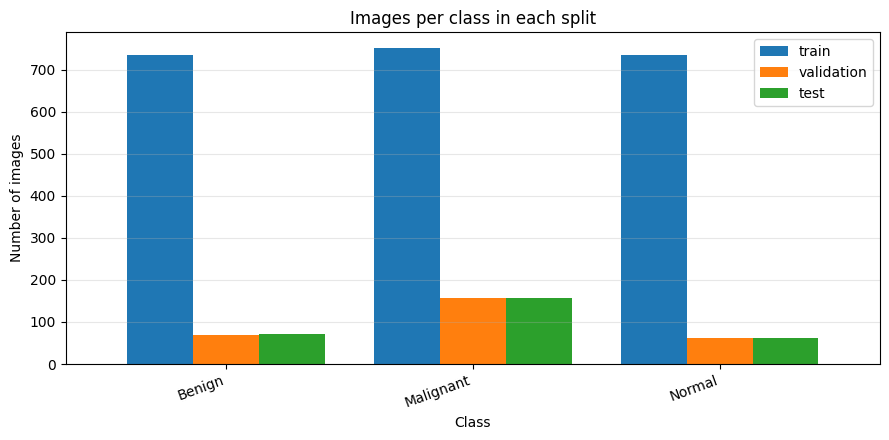

Training imbalance ratio (largest class / smallest class): 1.02
The training data is roughly balanced.
Class weights: {'Benign': 1.007, 'Malignant': 0.986, 'Normal': 1.007} -> USED in training


In [26]:
# ---- Class distribution per split ----
plot_df = counts_df.drop(index="TOTAL")
ax = plot_df.plot(kind="bar", figsize=(9, 4.5), width=0.8)
ax.set_title("Images per class in each split")
ax.set_xlabel("Class"); ax.set_ylabel("Number of images")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(GRAPHS_DIR / "class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

# ---- Imbalance summary (training split) ----
train_counts = counts_df.loc[CLASS_NAMES, "train"].astype(int)
imbalance_ratio = train_counts.max() / train_counts.min()
print(f"Training imbalance ratio (largest class / smallest class): {imbalance_ratio:.2f}")
if imbalance_ratio >= 1.5:
    print("The training data is noticeably imbalanced: watch macro-F1 and per-class recall, "
          "and consider USE_CLASS_WEIGHTS = True (keep it the same across compared experiments).")
else:
    print("The training data is roughly balanced.")

# ---- Class weights (only used when USE_CLASS_WEIGHTS = True) ----
# weight_c = total / (num_classes * count_c): rare classes get weight > 1.
CLASS_WEIGHTS = {i: float(train_counts.sum() / (NUM_CLASSES * train_counts[c])) for i, c in enumerate(CLASS_NAMES)}
CLASS_WEIGHT_ARG = CLASS_WEIGHTS if USE_CLASS_WEIGHTS else None
print("Class weights:", {CLASS_NAMES[i]: round(w, 3) for i, w in CLASS_WEIGHTS.items()},
      "-> USED in training" if USE_CLASS_WEIGHTS else "-> NOT used (USE_CLASS_WEIGHTS = False)")

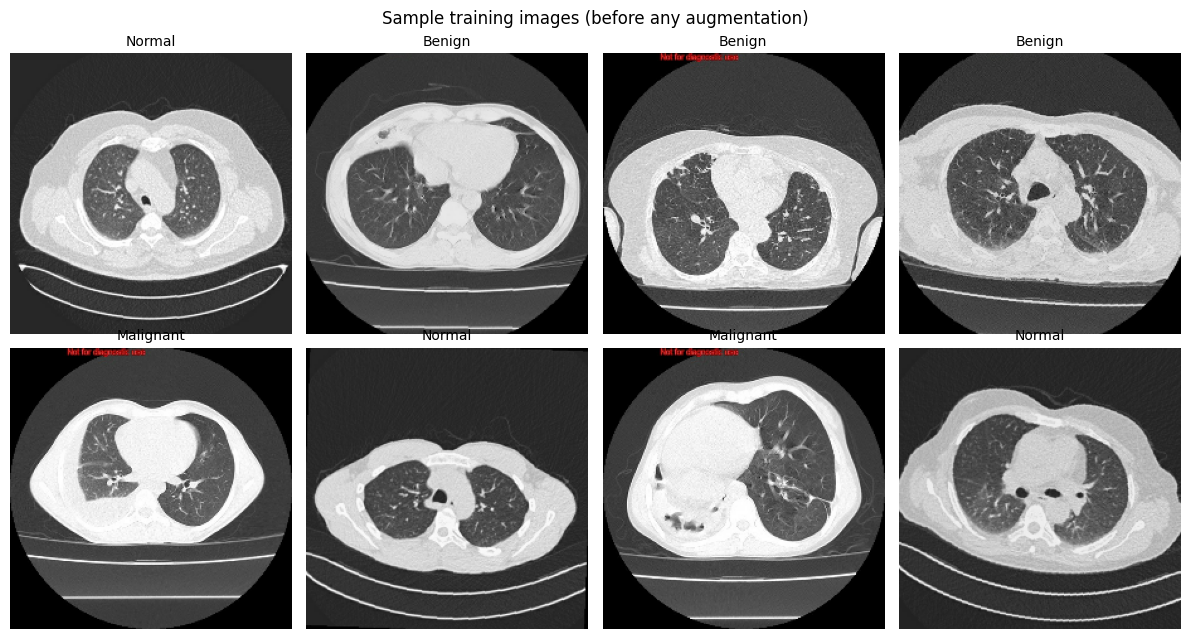

In [27]:
# ---- A few sample images from the training split ----
def to_class_ids(y):
    # Converts one-hot or integer labels to integer class ids.
    y = np.asarray(y)
    return np.argmax(y, axis=1) if y.ndim == 2 else y.astype(int)

sample_images, sample_labels = next(iter(raw_train))
sample_ids = to_class_ids(sample_labels)
n_show = min(8, len(sample_images))
fig, axes = plt.subplots(2, 4, figsize=(12, 6.5))
for ax in axes.ravel():
    ax.axis("off")
for ax, img, cid in zip(axes.ravel(), sample_images[:n_show], sample_ids[:n_show]):
    ax.imshow(img.numpy().astype("uint8"))
    ax.set_title(CLASS_NAMES[cid], fontsize=10)
plt.suptitle("Sample training images (before any augmentation)")
plt.tight_layout()
plt.savefig(GRAPHS_DIR / "sample_images.png", dpi=150, bbox_inches="tight")
plt.show()

In [28]:
# ---------------------------------------------------------------------
# Helper functions (plain NumPy / TensorFlow, no weights)
# ---------------------------------------------------------------------
def window_partition(x, H, W, C, ws):
    # (B, H, W, C) -> (B * num_windows, ws*ws, C): cuts the feature map into non-overlapping windows.
    x = tf.reshape(x, (-1, H // ws, ws, W // ws, ws, C))
    x = tf.transpose(x, (0, 1, 3, 2, 4, 5))
    return tf.reshape(x, (-1, ws * ws, C))

def window_reverse(w, H, W, C, ws):
    # (B * num_windows, ws*ws, C) -> (B, H, W, C): puts the windows back together.
    x = tf.reshape(w, (-1, H // ws, W // ws, ws, ws, C))
    x = tf.transpose(x, (0, 1, 3, 2, 4, 5))
    return tf.reshape(x, (-1, H, W, C))

def make_relative_index(ws):
    # For every pair of positions inside a window, the index of their relative offset (into the bias table).
    coords = np.stack(np.meshgrid(np.arange(ws), np.arange(ws), indexing="ij"))   # (2, ws, ws)
    coords = coords.reshape(2, -1)                                               # (2, N)
    rel = coords[:, :, None] - coords[:, None, :]                                # (2, N, N)
    rel = rel.transpose(1, 2, 0) + (ws - 1)                                      # shift offsets to start at 0
    rel[:, :, 0] *= 2 * ws - 1
    return rel.sum(-1).reshape(-1).astype("int32")                               # (N*N,)

def make_shift_mask(H, W, ws, shift):
    # After shifting the map, some windows contain tokens that were NOT neighbours in the image.
    # This mask (0 or -100) stops those tokens from attending to each other.
    img = np.zeros((1, H, W, 1), dtype="float32")
    regions = (slice(0, -ws), slice(-ws, -shift), slice(-shift, None))
    k = 0
    for h in regions:
        for w in regions:
            img[:, h, w, :] = k
            k += 1
    win = img.reshape(1, H // ws, ws, W // ws, ws, 1).transpose(0, 1, 3, 2, 4, 5).reshape(-1, ws * ws)
    diff = win[:, None, :] - win[:, :, None]                                     # (num_windows, N, N)
    return np.where(diff != 0, -100.0, 0.0).astype("float32")

print("Swin helper functions defined.")

Swin helper functions defined.


In [29]:
# ---------------------------------------------------------------------
# Custom layers
# ---------------------------------------------------------------------
class DropPath(layers.Layer):
    # Stochastic depth: during training, randomly drops the whole residual branch of each sample.
    def __init__(self, rate=0.0, **kwargs):
        super().__init__(**kwargs)
        self.rate = float(rate)

    def call(self, x, training=None):
        if not training or self.rate == 0.0:
            return x
        keep = 1.0 - self.rate
        shape = (tf.shape(x)[0],) + (1,) * (len(x.shape) - 1)    # one random number per sample
        mask = tf.floor(keep + tf.random.uniform(shape, dtype=x.dtype))
        return x / keep * mask

    def get_config(self):
        cfg = super().get_config(); cfg.update({"rate": self.rate}); return cfg


class WindowAttention(layers.Layer):
    # Component 2: multi-head self-attention INSIDE each window.
    # Input: (num_windows_total, N, C) where N = window_size * window_size tokens.
    def __init__(self, dim, num_heads, window_size, qkv_bias=True, use_rel_pos_bias=True,
                 attn_dropout=0.0, proj_dropout=0.0, **kwargs):
        super().__init__(**kwargs)
        self.dim, self.num_heads, self.window_size = dim, num_heads, window_size
        self.qkv_bias, self.use_rel_pos_bias = qkv_bias, use_rel_pos_bias
        self.attn_dropout, self.proj_dropout = attn_dropout, proj_dropout
        self.head_dim = dim // num_heads
        self.scale = self.head_dim ** -0.5
        self.qkv = layers.Dense(dim * 3, use_bias=qkv_bias, name="qkv")     # makes queries, keys, values
        self.proj = layers.Dense(dim, name="proj")                         # mixes the heads back together
        self.attn_drop = layers.Dropout(attn_dropout)
        self.proj_drop = layers.Dropout(proj_dropout)
        self.rel_index = make_relative_index(window_size)

    def build(self, input_shape):
        n = self.window_size ** 2
        if self.use_rel_pos_bias:
            # One learnable number per (relative offset, head).
            self.rel_table = self.add_weight(
                shape=((2 * self.window_size - 1) ** 2, self.num_heads),
                initializer=tf.keras.initializers.TruncatedNormal(stddev=0.02),
                trainable=True, name="rel_pos_bias_table")
        self.qkv.build((None, n, self.dim))
        self.proj.build((None, n, self.dim))
        super().build(input_shape)

    def call(self, x, attn_mask=None, training=None):
        n = self.window_size ** 2
        qkv = self.qkv(x)                                                   # (B_, N, 3C)
        qkv = tf.reshape(qkv, (-1, n, 3, self.num_heads, self.head_dim))
        qkv = tf.transpose(qkv, (2, 0, 3, 1, 4))                            # (3, B_, heads, N, head_dim)
        q, k, v = qkv[0], qkv[1], qkv[2]

        attn = tf.matmul(q * self.scale, k, transpose_b=True)               # (B_, heads, N, N)

        if self.use_rel_pos_bias:
            table = tf.convert_to_tensor(self.rel_table)
            bias = tf.gather(table, self.rel_index)                         # (N*N, heads)
            bias = tf.reshape(bias, (n, n, self.num_heads))
            bias = tf.transpose(bias, (2, 0, 1))                            # (heads, N, N)
            attn = attn + tf.expand_dims(bias, 0)

        if attn_mask is not None:                                           # only used by shifted windows
            n_win = attn_mask.shape[0]
            attn = tf.reshape(attn, (-1, n_win, self.num_heads, n, n))
            attn = attn + tf.cast(attn_mask, attn.dtype)[None, :, None, :, :]
            attn = tf.reshape(attn, (-1, self.num_heads, n, n))

        attn = tf.nn.softmax(attn, axis=-1)
        attn = self.attn_drop(attn, training=training)
        out = tf.matmul(attn, v)                                            # (B_, heads, N, head_dim)
        out = tf.reshape(tf.transpose(out, (0, 2, 1, 3)), (-1, n, self.dim))
        out = self.proj(out)
        return self.proj_drop(out, training=training)

    def get_config(self):
        cfg = super().get_config()
        cfg.update({"dim": self.dim, "num_heads": self.num_heads, "window_size": self.window_size,
                    "qkv_bias": self.qkv_bias, "use_rel_pos_bias": self.use_rel_pos_bias,
                    "attn_dropout": self.attn_dropout, "proj_dropout": self.proj_dropout})
        return cfg


class ShiftedWindowAttention(layers.Layer):
    # Component 3: window attention on a feature map, optionally with the cyclic SHIFT.
    #   shift_size = 0  -> regular window attention (W-MSA)
    #   shift_size > 0  -> shifted window attention (SW-MSA): roll the map, attend, roll back.
    # Input and output: (B, H, W, C) with H = W = resolution.
    def __init__(self, resolution, dim, num_heads, window_size, shift_size=0, qkv_bias=True,
                 use_rel_pos_bias=True, attn_dropout=0.0, proj_dropout=0.0, **kwargs):
        super().__init__(**kwargs)
        self.resolution, self.dim, self.num_heads = resolution, dim, num_heads
        self.window_size, self.shift_size = window_size, shift_size
        self.qkv_bias, self.use_rel_pos_bias = qkv_bias, use_rel_pos_bias
        self.attn_dropout, self.proj_dropout = attn_dropout, proj_dropout
        self.attn = WindowAttention(dim, num_heads, window_size, qkv_bias, use_rel_pos_bias,
                                    attn_dropout, proj_dropout, name="window_attention")
        self.shift_mask = make_shift_mask(resolution, resolution, window_size, shift_size) if shift_size > 0 else None

    def build(self, input_shape):
        self.attn.build((None, self.window_size ** 2, self.dim))
        super().build(input_shape)

    def call(self, x, training=None):
        H = W = self.resolution
        s = self.shift_size
        if s > 0:
            x = tf.roll(x, shift=[-s, -s], axis=[1, 2])                      # cyclic shift
        win = window_partition(x, H, W, self.dim, self.window_size)
        mask = tf.constant(self.shift_mask) if self.shift_mask is not None else None
        win = self.attn(win, attn_mask=mask, training=training)
        x = window_reverse(win, H, W, self.dim, self.window_size)
        if s > 0:
            x = tf.roll(x, shift=[s, s], axis=[1, 2])                        # undo the shift
        return x

    def get_config(self):
        cfg = super().get_config()
        cfg.update({"resolution": self.resolution, "dim": self.dim, "num_heads": self.num_heads,
                    "window_size": self.window_size, "shift_size": self.shift_size,
                    "qkv_bias": self.qkv_bias, "use_rel_pos_bias": self.use_rel_pos_bias,
                    "attn_dropout": self.attn_dropout, "proj_dropout": self.proj_dropout})
        return cfg


class PatchMerging(layers.Layer):
    # Component 5 (part 1): group each 2x2 neighbourhood of tokens and stack them along channels.
    # (B, H, W, C) -> (B, H/2, W/2, 4C). A LayerNorm + Dense then reduces 4C -> 2C (see patch_merging()).
    def call(self, x):
        x0 = x[:, 0::2, 0::2, :]
        x1 = x[:, 1::2, 0::2, :]
        x2 = x[:, 0::2, 1::2, :]
        x3 = x[:, 1::2, 1::2, :]
        return tf.concat([x0, x1, x2, x3], axis=-1)

# Register the layers by name (safe to re-run this cell; lets Keras find them when a saved model is loaded).
tf.keras.utils.get_custom_objects().update({
    "DropPath": DropPath, "WindowAttention": WindowAttention,
    "ShiftedWindowAttention": ShiftedWindowAttention, "PatchMerging": PatchMerging,
})
print("Swin custom layers defined.")

Swin custom layers defined.


In [30]:
# ---------------------------------------------------------------------
# Helper functions (plain NumPy / TensorFlow, no weights)
# ---------------------------------------------------------------------
def window_partition(x, H, W, C, ws):
    # (B, H, W, C) -> (B * num_windows, ws*ws, C): cuts the feature map into non-overlapping windows.
    x = tf.reshape(x, (-1, H // ws, ws, W // ws, ws, C))
    x = tf.transpose(x, (0, 1, 3, 2, 4, 5))
    return tf.reshape(x, (-1, ws * ws, C))

def window_reverse(w, H, W, C, ws):
    # (B * num_windows, ws*ws, C) -> (B, H, W, C): puts the windows back together.
    x = tf.reshape(w, (-1, H // ws, W // ws, ws, ws, C))
    x = tf.transpose(x, (0, 1, 3, 2, 4, 5))
    return tf.reshape(x, (-1, H, W, C))

def make_relative_index(ws):
    # For every pair of positions inside a window, the index of their relative offset (into the bias table).
    coords = np.stack(np.meshgrid(np.arange(ws), np.arange(ws), indexing="ij"))   # (2, ws, ws)
    coords = coords.reshape(2, -1)                                               # (2, N)
    rel = coords[:, :, None] - coords[:, None, :]                                # (2, N, N)
    rel = rel.transpose(1, 2, 0) + (ws - 1)                                      # shift offsets to start at 0
    rel[:, :, 0] *= 2 * ws - 1
    return rel.sum(-1).reshape(-1).astype("int32")                               # (N*N,)

def make_shift_mask(H, W, ws, shift):
    # After shifting the map, some windows contain tokens that were NOT neighbours in the image.
    # This mask (0 or -100) stops those tokens from attending to each other.
    img = np.zeros((1, H, W, 1), dtype="float32")
    regions = (slice(0, -ws), slice(-ws, -shift), slice(-shift, None))
    k = 0
    for h in regions:
        for w in regions:
            img[:, h, w, :] = k
            k += 1
    win = img.reshape(1, H // ws, ws, W // ws, ws, 1).transpose(0, 1, 3, 2, 4, 5).reshape(-1, ws * ws)
    diff = win[:, None, :] - win[:, :, None]                                     # (num_windows, N, N)
    return np.where(diff != 0, -100.0, 0.0).astype("float32")

print("Swin helper functions defined.")

# ---------------------------------------------------------------------
# Custom layers
# ---------------------------------------------------------------------
class DropPath(layers.Layer):
    # Stochastic depth: during training, randomly drops the whole residual branch of each sample.
    def __init__(self, rate=0.0, **kwargs):
        super().__init__(**kwargs)
        self.rate = float(rate)

    def call(self, x, training=None):
        if not training or self.rate == 0.0:
            return x
        keep = 1.0 - self.rate
        shape = (tf.shape(x)[0],) + (1,) * (len(x.shape) - 1)    # one random number per sample
        mask = tf.floor(keep + tf.random.uniform(shape, dtype=x.dtype))
        return x / keep * mask

    def get_config(self):
        cfg = super().get_config(); cfg.update({"rate": self.rate}); return cfg


class WindowAttention(layers.Layer):
    # Component 2: multi-head self-attention INSIDE each window.
    # Input: (num_windows_total, N, C) where N = window_size * window_size tokens.
    def __init__(self, dim, num_heads, window_size, qkv_bias=True, use_rel_pos_bias=True,
                 attn_dropout=0.0, proj_dropout=0.0, **kwargs):
        super().__init__(**kwargs)
        self.dim, self.num_heads, self.window_size = dim, num_heads, window_size
        self.qkv_bias, self.use_rel_pos_bias = qkv_bias, use_rel_pos_bias
        self.attn_dropout, self.proj_dropout = attn_dropout, proj_dropout
        self.head_dim = dim // num_heads
        self.scale = self.head_dim ** -0.5
        self.qkv = layers.Dense(dim * 3, use_bias=qkv_bias, name="qkv")     # makes queries, keys, values
        self.proj = layers.Dense(dim, name="proj")                         # mixes the heads back together
        self.attn_drop = layers.Dropout(attn_dropout)
        self.proj_drop = layers.Dropout(proj_dropout)
        self.rel_index = make_relative_index(window_size)

    def build(self, input_shape):
        n = self.window_size ** 2
        if self.use_rel_pos_bias:
            # One learnable number per (relative offset, head).
            self.rel_table = self.add_weight(
                shape=((2 * self.window_size - 1) ** 2, self.num_heads),
                initializer=tf.keras.initializers.TruncatedNormal(stddev=0.02),
                trainable=True, name="rel_pos_bias_table")
        self.qkv.build((None, n, self.dim))
        self.proj.build((None, n, self.dim))
        super().build(input_shape)

    def call(self, x, attn_mask=None, training=None):
        n = self.window_size ** 2
        qkv = self.qkv(x)                                                   # (B_, N, 3C)
        qkv = tf.reshape(qkv, (-1, n, 3, self.num_heads, self.head_dim))
        qkv = tf.transpose(qkv, (2, 0, 3, 1, 4))                            # (3, B_, heads, N, head_dim)
        q, k, v = qkv[0], qkv[1], qkv[2]

        attn = tf.matmul(q * self.scale, k, transpose_b=True)               # (B_, heads, N, N)

        if self.use_rel_pos_bias:
            table = tf.convert_to_tensor(self.rel_table)
            bias = tf.gather(table, self.rel_index)                         # (N*N, heads)
            bias = tf.reshape(bias, (n, n, self.num_heads))
            bias = tf.transpose(bias, (2, 0, 1))                            # (heads, N, N)
            attn = attn + tf.expand_dims(bias, 0)

        if attn_mask is not None:                                           # only used by shifted windows
            n_win = attn_mask.shape[0]
            attn = tf.reshape(attn, (-1, n_win, self.num_heads, n, n))
            attn = attn + tf.cast(attn_mask, attn.dtype)[None, :, None, :, :]
            attn = tf.reshape(attn, (-1, self.num_heads, n, n))

        attn = tf.nn.softmax(attn, axis=-1)
        attn = self.attn_drop(attn, training=training)
        out = tf.matmul(attn, v)                                            # (B_, heads, N, head_dim)
        out = tf.reshape(tf.transpose(out, (0, 2, 1, 3)), (-1, n, self.dim))
        out = self.proj(out)
        return self.proj_drop(out, training=training)

    def get_config(self):
        cfg = super().get_config()
        cfg.update({"dim": self.dim, "num_heads": self.num_heads, "window_size": self.window_size,
                    "qkv_bias": self.qkv_bias, "use_rel_pos_bias": self.use_rel_pos_bias,
                    "attn_dropout": self.attn_dropout, "proj_dropout": self.proj_dropout})
        return cfg


class ShiftedWindowAttention(layers.Layer):
    # Component 3: window attention on a feature map, optionally with the cyclic SHIFT.
    #   shift_size = 0  -> regular window attention (W-MSA)
    #   shift_size > 0  -> shifted window attention (SW-MSA): roll the map, attend, roll back.
    # Input and output: (B, H, W, C) with H = W = resolution.
    def __init__(self, resolution, dim, num_heads, window_size, shift_size=0, qkv_bias=True,
                 use_rel_pos_bias=True, attn_dropout=0.0, proj_dropout=0.0, **kwargs):
        super().__init__(**kwargs)
        self.resolution, self.dim, self.num_heads = resolution, dim, num_heads
        self.window_size, self.shift_size = window_size, shift_size
        self.qkv_bias, self.use_rel_pos_bias = qkv_bias, use_rel_pos_bias
        self.attn_dropout, self.proj_dropout = attn_dropout, proj_dropout
        self.attn = WindowAttention(dim, num_heads, window_size, qkv_bias, use_rel_pos_bias,
                                    attn_dropout, proj_dropout, name="window_attention")
        self.shift_mask = make_shift_mask(resolution, resolution, window_size, shift_size) if shift_size > 0 else None

    def build(self, input_shape):
        self.attn.build((None, self.window_size ** 2, self.dim))
        super().build(input_shape)

    def call(self, x, training=None):
        H = W = self.resolution
        s = self.shift_size
        if s > 0:
            x = tf.roll(x, shift=[-s, -s], axis=[1, 2])                      # cyclic shift
        win = window_partition(x, H, W, self.dim, self.window_size)
        mask = tf.constant(self.shift_mask) if self.shift_mask is not None else None
        win = self.attn(win, attn_mask=mask, training=training)
        x = window_reverse(win, H, W, self.dim, self.window_size)
        if s > 0:
            x = tf.roll(x, shift=[s, s], axis=[1, 2])                        # undo the shift
        return x

    def get_config(self):
        cfg = super().get_config()
        cfg.update({"resolution": self.resolution, "dim": self.dim, "num_heads": self.num_heads,
                    "window_size": self.window_size, "shift_size": self.shift_size,
                    "qkv_bias": self.qkv_bias, "use_rel_pos_bias": self.use_rel_pos_bias,
                    "attn_dropout": self.attn_dropout, "proj_dropout": self.proj_dropout})
        return cfg


class PatchMerging(layers.Layer):
    # Component 5 (part 1): group each 2x2 neighbourhood of tokens and stack them along channels.
    # (B, H, W, C) -> (B, H/2, W/2, 4C). A LayerNorm + Dense then reduces 4C -> 2C (see patch_merging()).
    def call(self, x):
        x0 = x[:, 0::2, 0::2, :]
        x1 = x[:, 1::2, 0::2, :]
        x2 = x[:, 0::2, 1::2, :]
        x3 = x[:, 1::2, 1::2, :]
        return tf.concat([x0, x1, x2, x3], axis=-1)

# Register the layers by name (safe to re-run this cell; lets Keras find them when a saved model is loaded).
tf.keras.utils.get_custom_objects().update({
    "DropPath": DropPath, "WindowAttention": WindowAttention,
    "ShiftedWindowAttention": ShiftedWindowAttention, "PatchMerging": PatchMerging,
})
print("Swin custom layers defined.")

# ---------------------------------------------------------------------
# Building blocks written as plain functions: tensor in -> tensor out
# ---------------------------------------------------------------------
def patch_embedding(x, cfg):
    # Component 1: cut the image into patch_size x patch_size patches and project each to embed_dim.
    # A Conv2D with kernel = stride = patch_size does exactly that.
    x = layers.Conv2D(cfg["embed_dim"], kernel_size=cfg["patch_size"], strides=cfg["patch_size"],
                      name="patch_embed_conv")(x)
    return layers.LayerNormalization(epsilon=1e-5, name="patch_embed_norm")(x)

def mlp_block(x, dim, cfg, name):
    # Component 4: two Dense layers with a GELU in between.
    hidden = int(dim * cfg["mlp_ratio"])
    x = layers.Dense(hidden, activation="gelu", name=f"{name}_mlp_fc1")(x)
    x = layers.Dropout(cfg["dropout_rate"], name=f"{name}_mlp_drop1")(x)
    x = layers.Dense(dim, name=f"{name}_mlp_fc2")(x)
    return layers.Dropout(cfg["dropout_rate"], name=f"{name}_mlp_drop2")(x)

def swin_block(x, res, dim, heads, cfg, shift, drop_path, name):
    # One Swin block = [LayerNorm -> (shifted) window attention -> residual] + [LayerNorm -> MLP -> residual]
    ws = min(cfg["window_size"], res)                 # if the map is smaller than the window, use one window
    shortcut = x
    y = layers.LayerNormalization(epsilon=1e-5, name=f"{name}_norm1")(x)
    y = ShiftedWindowAttention(res, dim, heads, ws, shift, cfg["qkv_bias"], cfg["use_relative_position_bias"],
                               cfg["attention_dropout_rate"], cfg["dropout_rate"], name=f"{name}_attn")(y)
    y = DropPath(drop_path, name=f"{name}_droppath1")(y)
    x = layers.Add(name=f"{name}_add1")([shortcut, y])

    shortcut = x
    y = layers.LayerNormalization(epsilon=1e-5, name=f"{name}_norm2")(x)
    y = mlp_block(y, dim, cfg, name)
    y = DropPath(drop_path, name=f"{name}_droppath2")(y)
    return layers.Add(name=f"{name}_add2")([shortcut, y])

def patch_merging(x, dim, name):
    # Component 5: halve the resolution, double the channels (dim -> 2*dim).
    x = PatchMerging(name=f"{name}_concat")(x)
    x = layers.LayerNormalization(epsilon=1e-5, name=f"{name}_norm")(x)
    return layers.Dense(2 * dim, use_bias=False, name=f"{name}_reduce")(x)

def classification_head(x, num_classes, head_cfg):
    # Component 6: shared by ALL models. feature map -> pooling -> [hidden layers] -> dropout -> softmax.
    pool = layers.GlobalMaxPooling2D if head_cfg["pooling"] == "max" else layers.GlobalAveragePooling2D
    x = pool(name="head_pool")(x)
    for i, units in enumerate(head_cfg["hidden_units"]):
        x = layers.Dense(units, activation=head_cfg["activation"], name=f"head_hidden{i + 1}")(x)
        x = layers.Dropout(head_cfg["dropout_rate"], name=f"head_hidden{i + 1}_dropout")(x)
    x = layers.Dropout(head_cfg["dropout_rate"], name="head_dropout")(x)
    # softmax output -> the loss functions below use from_logits=False
    return layers.Dense(num_classes, activation="softmax", dtype="float32", name="class_probabilities")(x)

def check_swin_config(cfg, image_size, label="SWIN_CONFIG"):
    # Catches impossible architectures BEFORE building, with an explanation of what to change.
    keys = ["patch_size", "window_size", "embed_dim", "num_heads", "depths", "mlp_ratio", "dropout_rate",
            "attention_dropout_rate", "drop_path_rate", "qkv_bias", "use_shifted_window", "use_relative_position_bias"]
    missing_keys = [k for k in keys if k not in cfg]
    if missing_keys:
        raise KeyError(f"{label} is missing keys: {missing_keys}")
    if image_size[0] != image_size[1]:
        raise ValueError("The Swin implementation expects a square IMAGE_SIZE, e.g. (224, 224).")
    if len(cfg["depths"]) != len(cfg["num_heads"]):
        raise ValueError(f"{label}: 'depths' and 'num_heads' must have the same length (one entry per stage).")
    if image_size[0] % cfg["patch_size"] != 0:
        raise ValueError(f"{label}: IMAGE_SIZE {image_size[0]} must be divisible by patch_size {cfg['patch_size']}.")
    for key in ("dropout_rate", "attention_dropout_rate", "drop_path_rate"):
        if not 0.0 <= cfg[key] < 1.0:
            raise ValueError(f"{label}: {key} must be in [0, 1).")
    res, ws = image_size[0] // cfg["patch_size"], cfg["window_size"]
    for s, (depth, heads) in enumerate(zip(cfg["depths"], cfg["num_heads"])):
        dim = cfg["embed_dim"] * 2 ** s
        if dim % heads != 0:
            raise ValueError(f"{label}: stage {s + 1} has {dim} channels, not divisible by {heads} heads. "
                             "Change embed_dim or num_heads.")
        if res > ws and res % ws != 0:
            raise ValueError(f"{label}: stage {s + 1} token grid is {res}x{res}, not divisible by window_size {ws}. "
                             "Change window_size, patch_size or IMAGE_SIZE.")
        if s < len(cfg["depths"]) - 1:
            if res % 2 != 0:
                raise ValueError(f"{label}: stage {s + 1} grid {res}x{res} cannot be halved by patch merging.")
            res //= 2

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_VAR  = [0.229 ** 2, 0.224 ** 2, 0.225 ** 2]

def build_swin(cfg, head_cfg, num_classes, image_size, name="Swin"):
    # Assembles the full Swin classifier from the components above.
    check_swin_config(cfg, image_size, label=name)
    inputs = layers.Input(shape=(*image_size, 3), name="image")
    x = layers.Rescaling(1.0 / 255, name="rescale")(inputs)                       # 0-255 -> 0-1
    x = layers.Normalization(mean=IMAGENET_MEAN, variance=IMAGENET_VAR, name="normalize")(x)
    x = patch_embedding(x, cfg)

    res, dim = image_size[0] // cfg["patch_size"], cfg["embed_dim"]
    total_blocks = sum(cfg["depths"])
    drop_rates = np.linspace(0.0, cfg["drop_path_rate"], total_blocks)             # grows with depth
    block_id = 0
    for stage, (depth, heads) in enumerate(zip(cfg["depths"], cfg["num_heads"])):
        for i in range(depth):
            # Odd blocks use the shifted window (unless disabled or the map fits in one window).
            shifted = cfg["use_shifted_window"] and (i % 2 == 1) and res > cfg["window_size"]
            shift = cfg["window_size"] // 2 if shifted else 0
            x = swin_block(x, res, dim, heads, cfg, shift, float(drop_rates[block_id]), f"stage{stage + 1}_block{i + 1}")
            block_id += 1
        if stage < len(cfg["depths"]) - 1:
            x = patch_merging(x, dim, f"stage{stage + 1}_merge")
            res, dim = res // 2, dim * 2

    x = layers.LayerNormalization(epsilon=1e-5, name="final_norm")(x)
    outputs = classification_head(x, num_classes, head_cfg)
    return tf.keras.Model(inputs, outputs, name=name)

print("Swin building blocks and build_swin() defined.")

Swin helper functions defined.
Swin custom layers defined.
Swin building blocks and build_swin() defined.


In [31]:
def run_swin_self_tests():
    # 1) window partition + reverse must give back the original tensor
    x = tf.random.normal((2, 14, 14, 8))
    back = window_reverse(window_partition(x, 14, 14, 8, 7), 14, 14, 8, 7)
    np.testing.assert_allclose(x.numpy(), back.numpy(), atol=1e-6)

    # 2) relative index and shift mask
    idx = make_relative_index(7)
    assert idx.shape == (49 * 49,) and idx.min() == 0 and idx.max() == (2 * 7 - 1) ** 2 - 1
    mask = make_shift_mask(14, 14, 7, 3)
    assert mask.shape == (4, 49, 49), mask.shape
    assert set(np.unique(mask).tolist()) <= {0.0, -100.0}
    assert (mask[0] == 0).all(), "the first window is not split by the shift and must be unmasked"

    # 3) tiny Swin: forward pass + one training step
    tiny = {"patch_size": 4, "window_size": 7, "embed_dim": 16, "num_heads": [2, 4], "depths": [2, 2],
            "mlp_ratio": 2.0, "dropout_rate": 0.1, "attention_dropout_rate": 0.1, "drop_path_rate": 0.1,
            "qkv_bias": True, "use_shifted_window": True, "use_relative_position_bias": True}
    head = {"pooling": "avg", "hidden_units": [8], "activation": "gelu", "dropout_rate": 0.1}
    model = build_swin(tiny, head, 3, (56, 56), name="tiny_swin")
    xb = np.random.uniform(0, 255, (4, 56, 56, 3)).astype("float32")
    p1 = model.predict(xb, verbose=0)
    assert p1.shape == (4, 3), p1.shape
    np.testing.assert_allclose(p1.sum(axis=1), 1.0, atol=1e-4)
    np.testing.assert_allclose(p1, model.predict(xb, verbose=0), atol=1e-5)       # 4) deterministic at inference
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy")
    loss = model.train_on_batch(xb, np.array([0, 1, 2, 0]))
    assert np.isfinite(np.asarray(loss)).all(), "training step produced a non-finite loss"

    # 5) ablation switches must also build
    for flag in ("use_shifted_window", "use_relative_position_bias"):
        variant = dict(tiny, **{flag: False})
        build_swin(variant, head, 3, (56, 56), name="tiny_variant")

    tf.keras.backend.clear_session(); gc.collect()
    print("All Swin self-tests passed.")

if RUN_SELF_TESTS:
    run_swin_self_tests()
else:
    print("Self-tests skipped (RUN_SELF_TESTS = False).")

All Swin self-tests passed.


In [32]:
def get_loss():
    # Returns the Keras loss object that matches LOSS_FUNCTION_NAME.
    name = LOSS_FUNCTION_NAME
    if name == "sparse_categorical_crossentropy":
        return tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False)
    if name in ("categorical_crossentropy", "categorical_crossentropy_label_smoothing"):
        smoothing = LABEL_SMOOTHING if name == "categorical_crossentropy_label_smoothing" else 0.0
        return tf.keras.losses.CategoricalCrossentropy(from_logits=False, label_smoothing=smoothing)
    if name == "categorical_focal_crossentropy":
        if not hasattr(tf.keras.losses, "CategoricalFocalCrossentropy"):
            raise RuntimeError("This TensorFlow/Keras version has no CategoricalFocalCrossentropy. "
                               "Choose another loss or upgrade TensorFlow.")
        return tf.keras.losses.CategoricalFocalCrossentropy(
            alpha=FOCAL_ALPHA, gamma=FOCAL_GAMMA, from_logits=False, label_smoothing=LABEL_SMOOTHING)
    raise ValueError(f"Unknown loss: {name}")

def get_metrics():
    # Accuracy metric whose label format matches the loss (names stay "accuracy" / "val_accuracy").
    if LABEL_MODE == "int":
        return [tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")]
    return [tf.keras.metrics.CategoricalAccuracy(name="accuracy")]

def get_optimizer(model_name=None):
    # A NEW optimizer object is needed for every model.
    name = OPTIMIZER_NAME.lower()
    lr = PRETRAINED_LEARNING_RATE if model_name == "SwinPretrained" else LEARNING_RATE
    wd = WEIGHT_DECAY if WEIGHT_DECAY > 0 else None
    if name == "adam":
        return tf.keras.optimizers.Adam(learning_rate=lr, weight_decay=wd)
    if name == "adamw":
        return tf.keras.optimizers.AdamW(learning_rate=lr, weight_decay=WEIGHT_DECAY)
    if name == "sgd":
        return tf.keras.optimizers.SGD(learning_rate=lr, momentum=SGD_MOMENTUM, weight_decay=wd)
    if name == "rmsprop":
        return tf.keras.optimizers.RMSprop(learning_rate=lr, weight_decay=wd)
    raise ValueError(f"Unknown optimizer: {OPTIMIZER_NAME}")

def compile_model(model, model_name=None):
    model.compile(optimizer=get_optimizer(model_name), loss=get_loss(), metrics=get_metrics())
    return model

# Fail early if the chosen loss/optimizer cannot be created in this TensorFlow version.
_ = get_loss(); _ = get_optimizer()
print("Loss     :", type(get_loss()).__name__, "| label_smoothing =", LABEL_SMOOTHING)
print("Optimizer:", type(get_optimizer()).__name__, f"| lr = {LEARNING_RATE} | weight_decay = {WEIGHT_DECAY}")
print("Labels   :", LABEL_MODE)

Loss     : CategoricalCrossentropy | label_smoothing = 0.05
Optimizer: Adam | lr = 0.01 | weight_decay = 0.0
Labels   : categorical


In [33]:
CNN_REGISTRY = {}
SWIN_CONFIGS = {"SwinBaseline": SWIN_BASELINE_CONFIG, **PROPOSED_CONFIGS}

def swin_cfg_for(model_name):
    return SWIN_CONFIGS.get(model_name)

def build_model(model_name):
    if model_name in SWIN_CONFIGS:
        return build_swin(SWIN_CONFIGS[model_name], HEAD_CONFIG, NUM_CLASSES, IMAGE_SIZE, name=model_name)
    if model_name == "SwinPretrained":
        try:
            model = keras_hub.models.SwinTransformerImageClassifier.from_preset(
                SWIN_PRESET, num_classes=NUM_CLASSES, activation="softmax",
                dropout=DROPOUT_RATE, compile=False,
            )
        except Exception as exc:
            raise RuntimeError(f"Cannot load {SWIN_PRESET}; enable Kaggle internet or set INCLUDE_PRETRAINED_SWIN=False.") from exc
        model.backbone.trainable = PRETRAINED_SWIN_TRAINABLE
        return model
    raise ValueError(f"Unknown model: {model_name}")

def count_params(model):
    return model.count_params(), int(sum(np.prod(v.shape) for v in model.trainable_weights))

MODEL_PARAMS = {}
smoke_images, _ = next(iter(raw_val))
for name in MODEL_NAMES:
    tf.keras.backend.clear_session(); gc.collect()
    model = compile_model(build_model(name), name)
    output = model.predict_on_batch(smoke_images[:2])
    if output.shape != (min(2, len(smoke_images)), NUM_CLASSES):
        raise ValueError(f"{name} output shape is {output.shape}")
    total, trainable = count_params(model)
    MODEL_PARAMS[name] = {"total": total, "trainable": trainable}
    print(f"{name}: {total / 1e6:.2f}M parameters | {trainable / 1e6:.2f}M trainable")
    if SHOW_FULL_SUMMARY:
        model.summary(line_length=110)
    del model
    tf.keras.backend.clear_session(); gc.collect()

SwinBaseline: 27.52M parameters | 27.52M trainable
SwinTransformer: 9.01M parameters | 9.01M trainable


/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:1039: UserWarning: Layer 'attn' (of type WindowAttention) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


SwinPretrained: 27.52M parameters | 27.52M trainable


In [34]:
# ---- Show the Swin structure(s) in a compact table ----
rows = []
for name in MODEL_NAMES:
    cfg = swin_cfg_for(name)
    if cfg is None:
        continue
    res, dim = IMAGE_SIZE[0] // cfg["patch_size"], cfg["embed_dim"]
    for s, (depth, heads) in enumerate(zip(cfg["depths"], cfg["num_heads"])):
        ws = min(cfg["window_size"], res)
        rows.append({"Model": name, "Stage": s + 1, "Token grid": f"{res}x{res}", "Channels": dim, "Heads": heads,
                     "Blocks": depth, "Window": ws,
                     "Shifted blocks": (depth // 2) if (cfg["use_shifted_window"] and res > cfg["window_size"]) else 0})
        res, dim = res // 2, dim * 2
if rows:
    display(pd.DataFrame(rows))
else:
    print("No Swin model selected in MODEL_NAMES.")

,Model,Stage,Token grid,Channels,Heads,Blocks,Window,Shifted blocks
0,SwinBaseline,1,56x56,96,3,2,7,1
1,SwinBaseline,2,28x28,192,6,2,7,1
2,SwinBaseline,3,14x14,384,12,6,7,3
3,SwinBaseline,4,7x7,768,24,2,7,0
4,SwinTransformer,1,56x56,64,2,2,7,1
5,SwinTransformer,2,28x28,128,4,2,7,1
6,SwinTransformer,3,14x14,256,8,4,7,2
7,SwinTransformer,4,7x7,512,16,2,7,0


In [35]:
def make_callbacks(model_name):
    checkpoint = str(Path(CHECKPOINTS_DIR) / f"{RUN_ID}_{model_name}_best.weights.h5")
    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(checkpoint, monitor="val_loss", mode="min", save_best_only=True, save_weights_only=True, verbose=1),
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=EARLY_STOPPING_PATIENCE, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.CSVLogger(str(HISTORIES_DIR / f"{model_name}_epochs.csv")),
    ]
    if LR_SCHEDULER == "reduce_on_plateau":
        callbacks.append(tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", mode="min", factor=REDUCE_LR_FACTOR, patience=REDUCE_LR_PATIENCE, min_lr=MIN_LEARNING_RATE, verbose=1))
    return callbacks, checkpoint

TRAINED_HISTORIES, TRAINING_SECONDS, CHECKPOINT_PATHS, TRAIN_INFO = {}, {}, {}, {}
for name in MODEL_NAMES:
    print(f"\nTraining {name}")
    tf.keras.backend.clear_session(); gc.collect(); tf.keras.utils.set_random_seed(SEED)
    model = compile_model(build_model(name), name)
    callbacks, checkpoint = make_callbacks(name)
    start = time.perf_counter()
    history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks, class_weight=CLASS_WEIGHT_ARG, verbose=2)
    TRAINING_SECONDS[name] = time.perf_counter() - start
    if not Path(checkpoint).is_file():
        raise FileNotFoundError(f"Best checkpoint was not saved: {checkpoint}")
    model.load_weights(checkpoint)
    CHECKPOINT_PATHS[name] = checkpoint
    TRAINED_HISTORIES[name] = {k: [float(v) for v in values] for k, values in history.history.items()}
    TRAIN_INFO[name] = {"best_epoch": int(np.argmin(history.history["val_loss"])) + 1, "best_val_loss": float(np.min(history.history["val_loss"]))}
    pd.DataFrame(TRAINED_HISTORIES[name]).to_csv(HISTORIES_DIR / f"{name}_history.csv", index_label="epoch")
    print(f"{name}: {len(history.history['loss'])} epochs, best epoch {TRAIN_INFO[name]['best_epoch']}, {TRAINING_SECONDS[name] / 60:.1f} min")
    del model, history
    tf.keras.backend.clear_session(); gc.collect()


Training SwinBaseline
Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(



Epoch 1: val_loss improved from None to 1.09596, saving model to /kaggle/working/Lung_Cancer_Classification_Results/checkpoints/20261126_120222_SwinBaseline_best.weights.h5

Epoch 1: finished saving model to /kaggle/working/Lung_Cancer_Classification_Results/checkpoints/20261126_120222_SwinBaseline_best.weights.h5
139/139 - 178s - 1s/step - accuracy: 0.3291 - loss: 1.9323 - val_accuracy: 0.5433 - val_loss: 1.0960 - learning_rate: 0.0100
Epoch 2/10

Epoch 2: val_loss did not improve from 1.09596
139/139 - 30s - 219ms/step - accuracy: 0.3350 - loss: 1.2344 - val_accuracy: 0.2145 - val_loss: 1.4190 - learning_rate: 0.0100
Epoch 3/10

Epoch 3: val_loss improved from 1.09596 to 1.08237, saving model to /kaggle/working/Lung_Cancer_Classification_Results/checkpoints/20261126_120222_SwinBaseline_best.weights.h5

Epoch 3: finished saving model to /kaggle/working/Lung_Cancer_Classification_Results/checkpoints/20261126_120222_SwinBaseline_best.weights.h5
139/139 - 31s - 222ms/step - accuracy: 0.

/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:1039: UserWarning: Layer 'attn' (of type WindowAttention) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


Epoch 1/10

Epoch 1: val_loss improved from None to 0.37657, saving model to /kaggle/working/Lung_Cancer_Classification_Results/checkpoints/20261126_120222_SwinPretrained_best.weights.h5

Epoch 1: finished saving model to /kaggle/working/Lung_Cancer_Classification_Results/checkpoints/20261126_120222_SwinPretrained_best.weights.h5
139/139 - 180s - 1s/step - accuracy: 0.8294 - loss: 0.4799 - val_accuracy: 0.9100 - val_loss: 0.3766 - learning_rate: 1.0000e-05
Epoch 2/10

Epoch 2: val_loss improved from 0.37657 to 0.34302, saving model to /kaggle/working/Lung_Cancer_Classification_Results/checkpoints/20261126_120222_SwinPretrained_best.weights.h5

Epoch 2: finished saving model to /kaggle/working/Lung_Cancer_Classification_Results/checkpoints/20261126_120222_SwinPretrained_best.weights.h5
139/139 - 34s - 241ms/step - accuracy: 0.9325 - loss: 0.3172 - val_accuracy: 0.9031 - val_loss: 0.3430 - learning_rate: 1.0000e-05
Epoch 3/10

Epoch 3: val_loss improved from 0.34302 to 0.32688, saving mo

In [36]:
def to_class_ids(labels):
    labels = np.asarray(labels)
    return np.argmax(labels, axis=1) if labels.ndim == 2 else labels.astype(int)

def predict_with_labels(model, dataset):
    probabilities, labels = [], []
    for images, y in dataset:
        probabilities.append(model.predict_on_batch(images))
        labels.append(to_class_ids(y.numpy()))
    return np.concatenate(probabilities).astype("float64"), np.concatenate(labels)

def calc_metrics(y_true, probs):
    pred = probs.argmax(axis=1)
    auc = np.nan
    try:
        auc = roc_auc_score(y_true, probs[:, 1]) if NUM_CLASSES == 2 else roc_auc_score(y_true, probs, labels=np.arange(NUM_CLASSES), multi_class="ovr", average="macro")
    except ValueError as exc:
        print("ROC-AUC unavailable:", exc)
    cm = confusion_matrix(y_true, pred, labels=np.arange(NUM_CLASSES))
    specificity = []
    for i in range(NUM_CLASSES):
        tp = cm[i, i]; fn = cm[i, :].sum() - tp; fp = cm[:, i].sum() - tp
        tn = cm.sum() - tp - fn - fp
        specificity.append(tn / (tn + fp) if tn + fp else np.nan)
    return {
        "accuracy": accuracy_score(y_true, pred) * 100,
        "precision_macro": precision_score(y_true, pred, average="macro", zero_division=0) * 100,
        "recall_macro": recall_score(y_true, pred, average="macro", zero_division=0) * 100,
        "specificity_macro": float(np.nanmean(specificity)) * 100,
        "f1_macro": f1_score(y_true, pred, average="macro", zero_division=0) * 100,
        "roc_auc_macro": auc,
        "average_precision_macro": average_precision_score(np.eye(NUM_CLASSES)[y_true], probs, average="macro"),
    }

EVAL_RESULTS, reference_val, reference_test = {}, None, None
for name in MODEL_NAMES:
    tf.keras.backend.clear_session(); gc.collect()
    model = compile_model(build_model(name), name)
    model.load_weights(CHECKPOINT_PATHS[name])
    val_probs, y_val = predict_with_labels(model, val_ds)
    test_probs, y_test = predict_with_labels(model, test_ds)
    if reference_val is None:
        reference_val, reference_test = y_val.copy(), y_test.copy()
    if not np.array_equal(y_val, reference_val) or not np.array_equal(y_test, reference_test):
        raise ValueError("Evaluation label ordering differs across models.")
    val_loss = float(model.evaluate(val_ds, verbose=0, return_dict=True)["loss"])
    test_pred = test_probs.argmax(axis=1)
    EVAL_RESULTS[name] = {"val": calc_metrics(y_val, val_probs), "test": calc_metrics(y_test, test_probs), "val_loss": val_loss, "val_probs": val_probs, "test_probs": test_probs, "cm": confusion_matrix(y_test, test_pred, labels=np.arange(NUM_CLASSES))}
    report = classification_report(y_test, test_pred, labels=np.arange(NUM_CLASSES), target_names=CLASS_NAMES, output_dict=True, zero_division=0)
    pd.DataFrame(report).T.to_csv(METRICS_DIR / f"{name}_classification_report.csv")
    pred_df = pd.DataFrame(test_probs, columns=[f"prob_{c}" for c in CLASS_NAMES])
    pred_df.insert(0, "predicted_class", [CLASS_NAMES[i] for i in test_pred])
    pred_df.insert(0, "true_class", [CLASS_NAMES[i] for i in y_test])
    pred_df.to_csv(PREDICTIONS_DIR / f"{name}_test_predictions.csv", index=False)
    print(f"\n{name}: test classification report")
    print(classification_report(y_test, test_pred, labels=np.arange(NUM_CLASSES), target_names=CLASS_NAMES, digits=3, zero_division=0))
    del model
    tf.keras.backend.clear_session(); gc.collect()

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 348 variables. 
  saveable.load_own_variables(store)



SwinBaseline: test classification report
              precision    recall  f1-score   support

      Benign      0.000     0.000     0.000        71
   Malignant      0.541     1.000     0.702       158
      Normal      0.000     0.000     0.000        63

    accuracy                          0.541       292
   macro avg      0.180     0.333     0.234       292
weighted avg      0.293     0.541     0.380       292



/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 296 variables. 
  saveable.load_own_variables(store)



SwinTransformer: test classification report
              precision    recall  f1-score   support

      Benign      0.000     0.000     0.000        71
   Malignant      0.541     1.000     0.702       158
      Normal      0.000     0.000     0.000        63

    accuracy                          0.541       292
   macro avg      0.180     0.333     0.234       292
weighted avg      0.293     0.541     0.380       292



/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:1039: UserWarning: Layer 'attn' (of type WindowAttention) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 348 variables. 
  saveable.load_own_variables(store)



SwinPretrained: test classification report
              precision    recall  f1-score   support

      Benign      0.903     0.915     0.909        71
   Malignant      0.962     0.956     0.959       158
      Normal      1.000     1.000     1.000        63

    accuracy                          0.955       292
   macro avg      0.955     0.957     0.956       292
weighted avg      0.956     0.955     0.956       292



,Validation Loss,Validation accuracy,Validation precision_macro,Validation recall_macro,Validation specificity_macro,Validation f1_macro,Validation roc_auc_macro,Validation average_precision_macro,Test accuracy,Test precision_macro,Test recall_macro,Test specificity_macro,Test f1_macro,Test roc_auc_macro,Test average_precision_macro,Parameters (M),Trainable Parameters (M),Training Time (min),Best Epoch
Model,,,,,,,,,,,,,,,,,,,
SwinPretrained,0.211,98.616,99.172,98.095,98.990,98.600,0.999,0.998,95.548,95.485,95.706,97.452,95.594,0.994,0.989,27.522,27.522,7.779,9
SwinBaseline,1.059,54.325,18.108,33.333,66.667,23.468,0.451,0.317,54.110,18.037,33.333,66.667,23.407,0.435,0.324,27.522,27.522,7.453,7
SwinTransformer,1.016,54.325,18.108,33.333,66.667,23.468,0.541,0.384,54.110,18.037,33.333,66.667,23.407,0.539,0.412,9.013,9.013,5.148,3


,Validation Macro-F1 Delta (pp),Test Accuracy Delta (pp),Test Macro-F1 Delta (pp)
Proposed Model,,,
SwinTransformer,0.0,0.0,0.0


SwinTransformer matches validation macro-F1 by 0.00 pp.


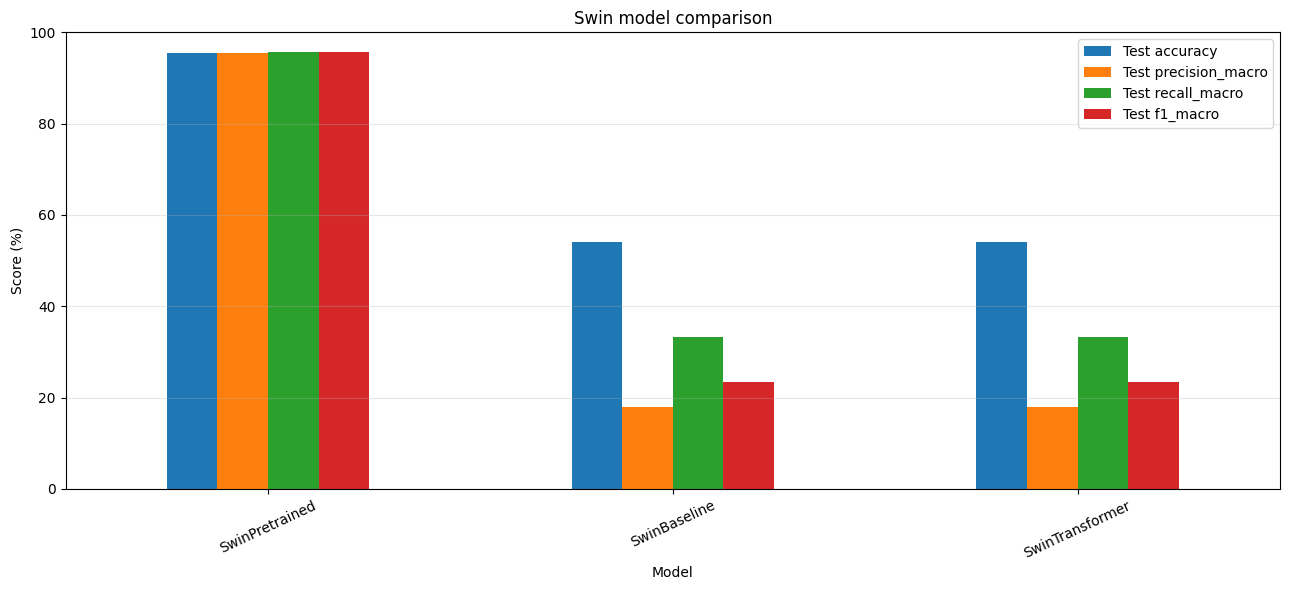

In [37]:
rows = []
for name, result in EVAL_RESULTS.items():
    row = {"Model": name, "Validation Loss": result["val_loss"]}
    row.update({f"Validation {k}": v for k, v in result["val"].items()})
    row.update({f"Test {k}": v for k, v in result["test"].items()})
    row.update({"Parameters (M)": MODEL_PARAMS[name]["total"] / 1e6, "Trainable Parameters (M)": MODEL_PARAMS[name]["trainable"] / 1e6, "Training Time (min)": TRAINING_SECONDS[name] / 60, "Best Epoch": TRAIN_INFO[name]["best_epoch"]})
    rows.append(row)
comparison_df = pd.DataFrame(rows).set_index("Model").sort_values("Validation f1_macro", ascending=False)
display(comparison_df.round(3))
comparison_df.to_csv(METRICS_DIR / "model_comparison.csv")

if "SwinBaseline" in comparison_df.index:
    baseline = comparison_df.loc["SwinBaseline"]
    delta_rows = []
    for name in PROPOSED_CONFIGS:
        if name in comparison_df.index:
            proposed = comparison_df.loc[name]
            delta_rows.append({
                "Proposed Model": name,
                "Validation Macro-F1 Delta (pp)": proposed["Validation f1_macro"] - baseline["Validation f1_macro"],
                "Test Accuracy Delta (pp)": proposed["Test accuracy"] - baseline["Test accuracy"],
                "Test Macro-F1 Delta (pp)": proposed["Test f1_macro"] - baseline["Test f1_macro"],
            })
    if delta_rows:
        display(pd.DataFrame(delta_rows).set_index("Proposed Model").round(3))
        for row in delta_rows:
            direction = "improves" if row["Validation Macro-F1 Delta (pp)"] > 0 else "reduces" if row["Validation Macro-F1 Delta (pp)"] < 0 else "matches"
            print(f"{row['Proposed Model']} {direction} validation macro-F1 by {abs(row['Validation Macro-F1 Delta (pp)']):.2f} pp.")
metric_cols = ["Test accuracy", "Test precision_macro", "Test recall_macro", "Test f1_macro"]
ax = comparison_df[metric_cols].plot(kind="bar", figsize=(13, 6), ylim=(0, 100), rot=25)
ax.set(title="Swin model comparison", ylabel="Score (%)")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig(GRAPHS_DIR / "model_metric_comparison.png", dpi=160, bbox_inches="tight"); plt.show()

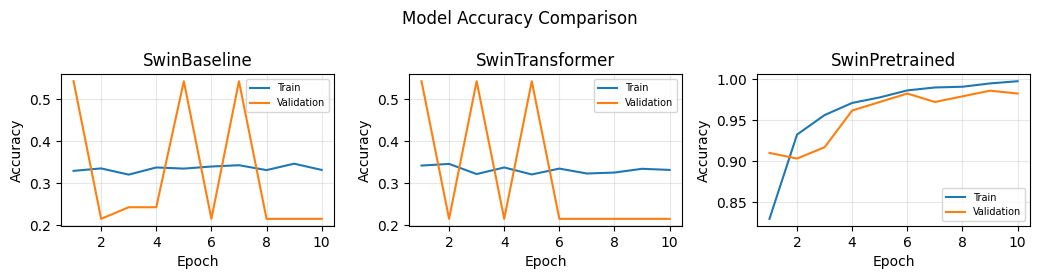

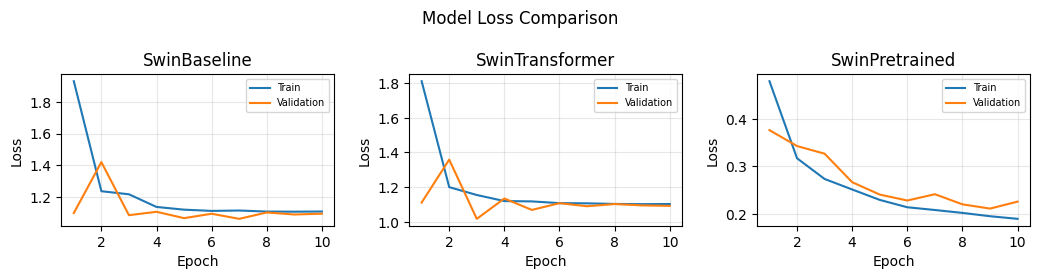

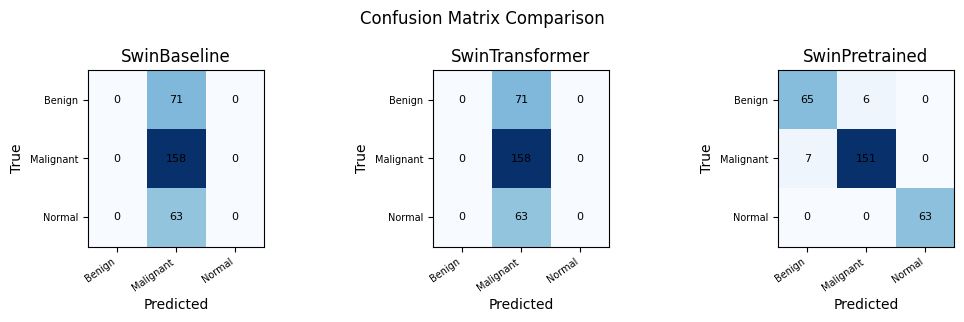

All comparison collages saved successfully!


In [41]:
# 1. Accuracy Comparison Collage
num_models = len(TRAINED_HISTORIES)
cols = num_models

fig, axes = plt.subplots(1, cols, figsize=(3.5 * cols, 2.8), squeeze=False)

for i, (name, history) in enumerate(TRAINED_HISTORIES.items()):
    ax = axes[0, i]
    epochs = range(1, len(history["accuracy"]) + 1)

    ax.plot(epochs, history["accuracy"], label="Train")
    ax.plot(epochs, history["val_accuracy"], label="Validation")
    ax.set(title=name, xlabel="Epoch", ylabel="Accuracy")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)

fig.suptitle("Model Accuracy Comparison", fontsize=12)
fig.tight_layout()
fig.savefig(GRAPHS_DIR / "accuracy_comparison.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

# 2. Loss Comparison Collage
fig, axes = plt.subplots(1, cols, figsize=(3.5 * cols, 2.8), squeeze=False)

for i, (name, history) in enumerate(TRAINED_HISTORIES.items()):
    ax = axes[0, i]
    epochs = range(1, len(history["loss"]) + 1)

    ax.plot(epochs, history["loss"], label="Train")
    ax.plot(epochs, history["val_loss"], label="Validation")
    ax.set(title=name, xlabel="Epoch", ylabel="Loss")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)

fig.suptitle("Model Loss Comparison", fontsize=12)
fig.tight_layout()
fig.savefig(GRAPHS_DIR / "loss_comparison.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

# 3. Confusion Matrix Comparison Collage
num_models = len(EVAL_RESULTS)

fig, axes = plt.subplots(
    1, num_models,
    figsize=(3.5 * num_models, 3.2),
    squeeze=False
)

for i, (name, result) in enumerate(EVAL_RESULTS.items()):
    ax = axes[0, i]
    cm = result["cm"]

    ax.imshow(cm, cmap="Blues")
    ax.set(
        title=name,
        xlabel="Predicted",
        ylabel="True",
        xticks=range(NUM_CLASSES),
        yticks=range(NUM_CLASSES),
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES
    )

    ax.tick_params(labelsize=7)
    plt.setp(ax.get_xticklabels(), rotation=35, ha="right")

    for r in range(NUM_CLASSES):
        for c in range(NUM_CLASSES):
            ax.text(c, r, str(cm[r, c]), ha="center", va="center", fontsize=8)

fig.suptitle("Confusion Matrix Comparison", fontsize=12)
fig.tight_layout()
fig.savefig(GRAPHS_DIR / "confusion_matrices.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

print("All comparison collages saved successfully!")

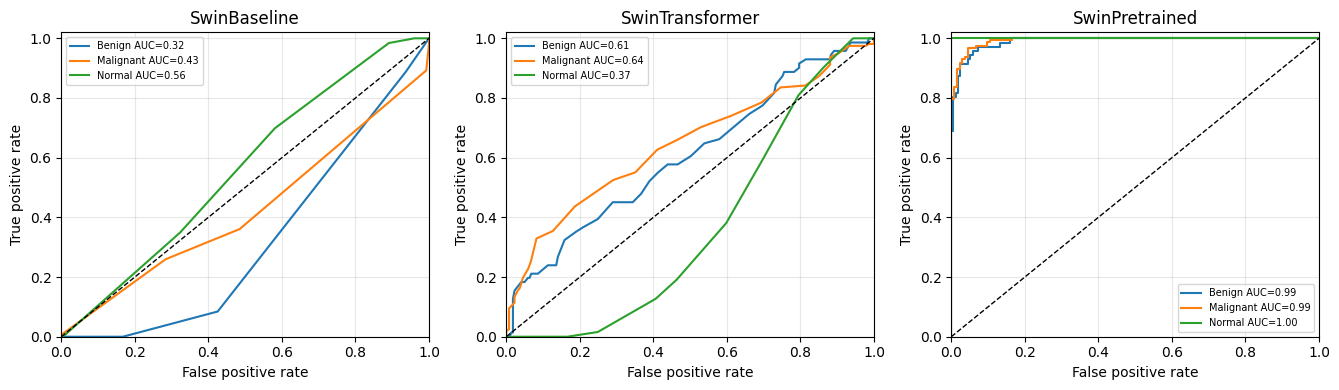

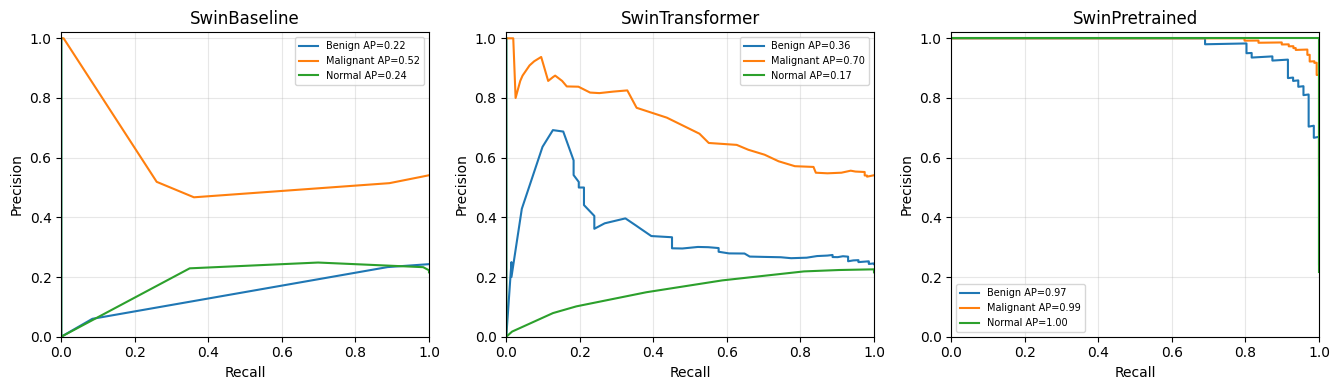

In [39]:
# One-vs-rest ROC and precision-recall curves on the held-out test split.
cols = min(4, len(EVAL_RESULTS)); rows = (len(EVAL_RESULTS) + cols - 1) // cols
y_onehot = np.eye(NUM_CLASSES)[reference_test]
fig_roc, axes_roc = plt.subplots(rows, cols, figsize=(4.5 * cols, 4 * rows), squeeze=False)
fig_pr, axes_pr = plt.subplots(rows, cols, figsize=(4.5 * cols, 4 * rows), squeeze=False)
for i, (name, result) in enumerate(EVAL_RESULTS.items()):
    roc_ax, pr_ax = axes_roc[i // cols, i % cols], axes_pr[i // cols, i % cols]
    probs = result["test_probs"]
    for class_id, class_name in enumerate(CLASS_NAMES):
        fpr, tpr, _ = roc_curve(y_onehot[:, class_id], probs[:, class_id])
        auc = roc_auc_score(y_onehot[:, class_id], probs[:, class_id])
        roc_ax.plot(fpr, tpr, label=f"{class_name} AUC={auc:.2f}")
        precision, recall, _ = precision_recall_curve(y_onehot[:, class_id], probs[:, class_id])
        ap = average_precision_score(y_onehot[:, class_id], probs[:, class_id])
        pr_ax.plot(recall, precision, label=f"{class_name} AP={ap:.2f}")
    roc_ax.plot([0, 1], [0, 1], "k--", linewidth=1)
    roc_ax.set(title=name, xlabel="False positive rate", ylabel="True positive rate", xlim=(0, 1), ylim=(0, 1.02))
    pr_ax.set(title=name, xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1.02))
    roc_ax.legend(fontsize=7); pr_ax.legend(fontsize=7)
    roc_ax.grid(alpha=0.3); pr_ax.grid(alpha=0.3)
for i in range(len(EVAL_RESULTS), rows * cols): axes_roc[i // cols, i % cols].axis("off"); axes_pr[i // cols, i % cols].axis("off")
fig_roc.tight_layout(); fig_pr.tight_layout()
fig_roc.savefig(GRAPHS_DIR / "roc_curves.png", dpi=160, bbox_inches="tight")
fig_pr.savefig(GRAPHS_DIR / "precision_recall_curves.png", dpi=160, bbox_inches="tight")
plt.show(); plt.show()

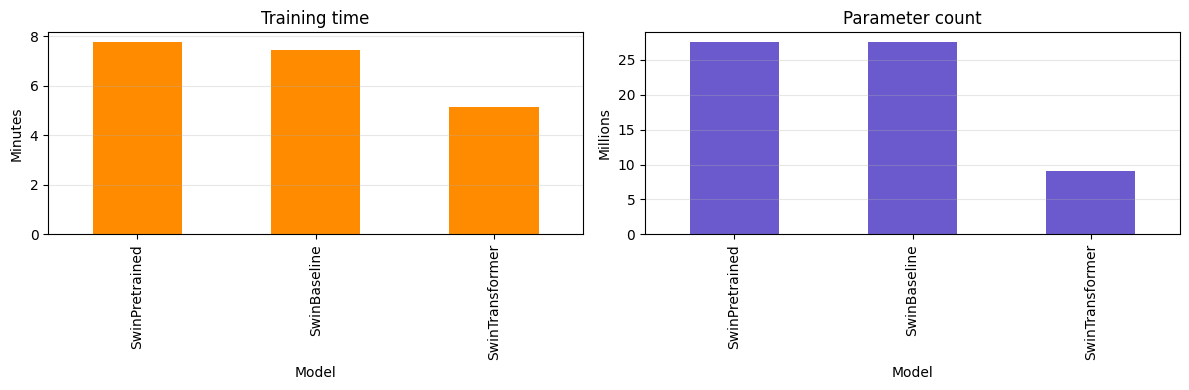

Selected by validation macro-F1: SwinPretrained
Validation macro-F1: 98.60% | Test accuracy: 95.55% | Test macro-F1: 95.59%
95% test accuracy: reached in this run
Saved weights: /kaggle/working/Lung_Cancer_Classification_Results/models
Experiment log: /kaggle/working/Lung_Cancer_Classification_Results/experiment_log.csv
All outputs saved in: /kaggle/working/Lung_Cancer_Classification_Results/run_20261126_120222


In [40]:
# Training time, model size, and summary verdict.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
comparison_df["Training Time (min)"].plot(kind="bar", ax=axes[0], color="darkorange")
axes[0].set(title="Training time", ylabel="Minutes"); axes[0].grid(axis="y", alpha=0.3)
comparison_df["Parameters (M)"].plot(kind="bar", ax=axes[1], color="slateblue")
axes[1].set(title="Parameter count", ylabel="Millions"); axes[1].grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig(GRAPHS_DIR / "time_and_parameters.png", dpi=160, bbox_inches="tight"); plt.show()

best_name = comparison_df["Validation f1_macro"].idxmax()
best = comparison_df.loc[best_name]
print("Selected by validation macro-F1:", best_name)
print(f"Validation macro-F1: {best['Validation f1_macro']:.2f}% | Test accuracy: {best['Test accuracy']:.2f}% | Test macro-F1: {best['Test f1_macro']:.2f}%")
print("95% test accuracy:", "reached in this run" if best["Test accuracy"] >= 95 else "not reached in this run")

import shutil
for name, checkpoint in CHECKPOINT_PATHS.items():
    shutil.copy2(checkpoint, Path(MODELS_DIR) / f"{RUN_ID}_{name}_best.weights.h5")
with (Path(MODELS_DIR) / f"{RUN_ID}_class_names.json").open("w") as f:
    json.dump(CLASS_NAMES, f, indent=2)

experiment_config = {
    "run_id": RUN_ID, "seed": SEED, "models": MODEL_NAMES, "dataset_root": str(DATASET_ROOT),
    "class_names": CLASS_NAMES, "image_counts": counts_df.to_dict(), "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE, "epochs": EPOCHS, "learning_rate": LEARNING_RATE,
    "optimizer": OPTIMIZER_NAME, "weight_decay": WEIGHT_DECAY, "scheduler": LR_SCHEDULER,
    "loss": LOSS_FUNCTION_NAME, "label_smoothing": LABEL_SMOOTHING,
    "augmentation": USE_AUGMENTATION, "class_weights": USE_CLASS_WEIGHTS,
    "swin_baseline_config": SWIN_BASELINE_CONFIG, "proposed_configs": PROPOSED_CONFIGS,
    "pretrained_swin_preset": SWIN_PRESET if INCLUDE_PRETRAINED_SWIN else None,
    "selection_metric": "validation macro-F1", "test_used_for_selection": False,
    "model_parameters": MODEL_PARAMS, "checkpoint_paths": CHECKPOINT_PATHS,
}
with (RUN_DIR / "experiment_config.json").open("w") as f: json.dump(experiment_config, f, indent=2, default=str)
comparison_df.to_json(METRICS_DIR / "model_comparison.json", orient="table", indent=2)
log_path = Path(RESULTS_DIR) / "experiment_log.csv"
run_log = comparison_df.reset_index()
run_log.insert(0, "Run ID", RUN_ID)
if log_path.exists():
    run_log = pd.concat([pd.read_csv(log_path), run_log], ignore_index=True, sort=False)
run_log.to_csv(log_path, index=False)
print("Saved weights:", MODELS_DIR)
print("Experiment log:", log_path)
print("All outputs saved in:", RUN_DIR)